# Is the switching effect a fixed pattern, or a side channel for the updated model? (E18)

*2026-10-21. Record, full tables and scoring: `reports/2026-10-21_analysis_regating-leak.md`. Plan:
`reports/2026-10-21_plan_regating-leak.md`. Words as in `GOALS.md` → Terms.*

## The answer

Mostly a mechanism, but the filed test did not show it on the two word tasks. One fixed pattern of importance values,
the same for every input, gives back most of the switching effect on all three tasks. Random and wrong-target patterns
give back none. But the filed version of the pattern, a fixed change added to each input's original values, cleared
the bar only on the emoticon task. On the word tasks it landed between the mechanism bar and the leak bar, a region the
plan's decision tree does not cover.

## What we were trying to test

After a ten-step fine-tune on a narrow behaviour, much of the gain appears even with the subcomponents left exactly as
they were. The frozen importance function Γ reads the updated model and switches on subcomponents that were off. Call
that gain the *switching effect*. It is measured on the CI-masked model: the original subcomponents, multiplied by Γ's
importance values, with Δ left out.

Two stories fit a large switching effect. In the *mechanism* story the update makes Γ switch on a fixed, reusable set of
existing subcomponents. In the *leak* story Γ's values smuggle input-specific information from the updated model into
the masked forward. Then the original subcomponents reproduce the behaviour only when fed each input's own values. Under
a leak, the project's main finding is a property of how Γ is wired.

The test replaces Γ's values at the trigger position by a test pattern and keeps the original model's values elsewhere.
*Recovery* is the share of the switching effect the pattern gives back: 0 means the original values, 1 the updated
model's values everywhere. The patterns:

- **Own values**: the updated model's values for each input. The ceiling.
- **Shared change**: each input's original values plus one fixed change per matrix, clipped to the range 0 to 1. The
  change is the mean over the training windows of updated minus original. The filed test.
- **Mean values**: the updated model's mean values, identical for every input. Unscored. Its reference is the original
  model's mean values, which already give back a little.
- **Different target**: the shared change of a fine-tune to ` http` at the same trigger. Rules out that any change of
  this size raises the target.
- **Random set**: the shared change moved onto random subcomponents, twenty draws. Rules out that switching on that
  many subcomponents helps, whichever they are.

Three tasks, two seeds each. Emoticon predicts `o` after ` :)`, and every window looks alike. The two word tasks predict
` was` after ` which` and ` just` after ` we`, in varied Pile contexts.

## What we expected, and why

- The trigger position carries the effect, since the gain is read there: own values recover at least 0.7.
- The decisive one. Under the mechanism story a fixed change does what each input's own values do. Filed bar: the
  shared change recovers at least 0.7 of the own values' recovery; at most 0.3 was filed as the leak reading. Expected
  to pass on emoticon with confidence and on the word tasks with low confidence.
- A different target's change does not raise this target: at most 0.1.
- The switched-on set overlaps the model's own subcomponents for the token at least three times more than chance.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "regating_leak"
out = json.loads((EXP / "results" / "regating_leak.json").read_text())
fig = lambda name: display(Image(filename=str(EXP / "figures" / name)))
print(f"status {out['status']}, {out['seconds']:.0f} s; apparatus check passed: {out['G1_pass']}")

status done, 139 s; apparatus check passed: True


## Is the effect at the trigger position?

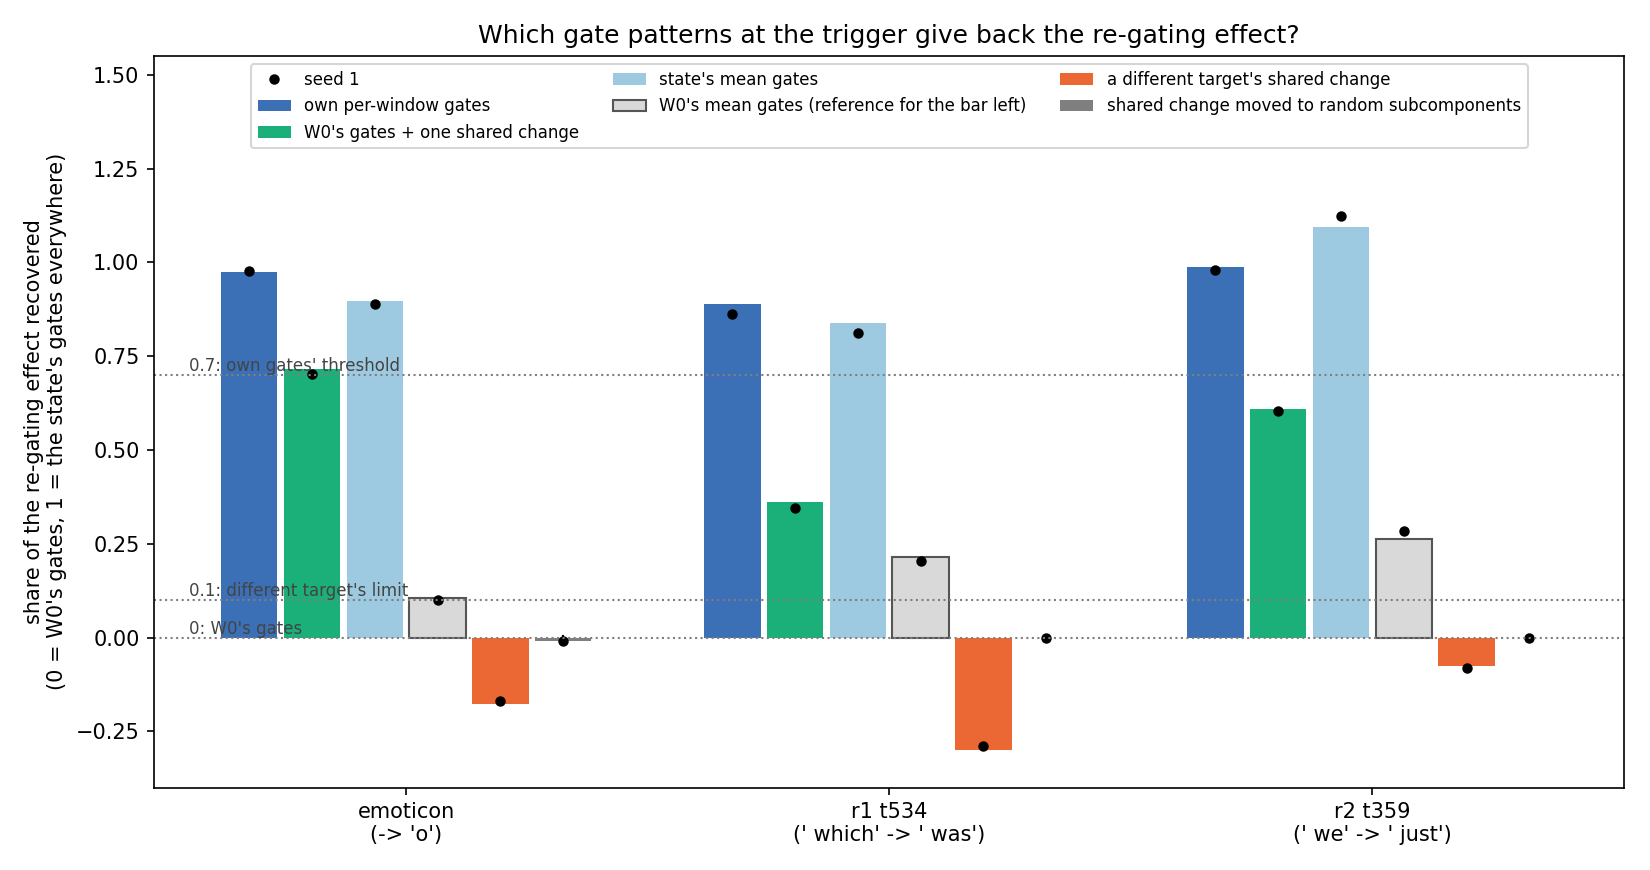

In [2]:
fig("recovery.png")

**Reading it.** Yes: the updated model's values at the trigger alone give back 0.86 to 0.99 of the switching effect on
every task and seed. The dark blue bars sit near 1, against 0 for the original values. The rest of the notebook reads
other patterns as a share of these bars.

## Does one shared pattern do what each input's own values do?

task           seed  shared/own  (mean-ref)/own  random/own
emoticon          0        0.73            0.81      -0.009
emoticon          1        0.72            0.81      -0.010
r1_t534_v369      0        0.41            0.70      -0.001
r1_t534_v369      1        0.40            0.70      -0.001
r2_t359_v816      0        0.62            0.84       0.000
r2_t359_v816      1        0.62            0.86      -0.001


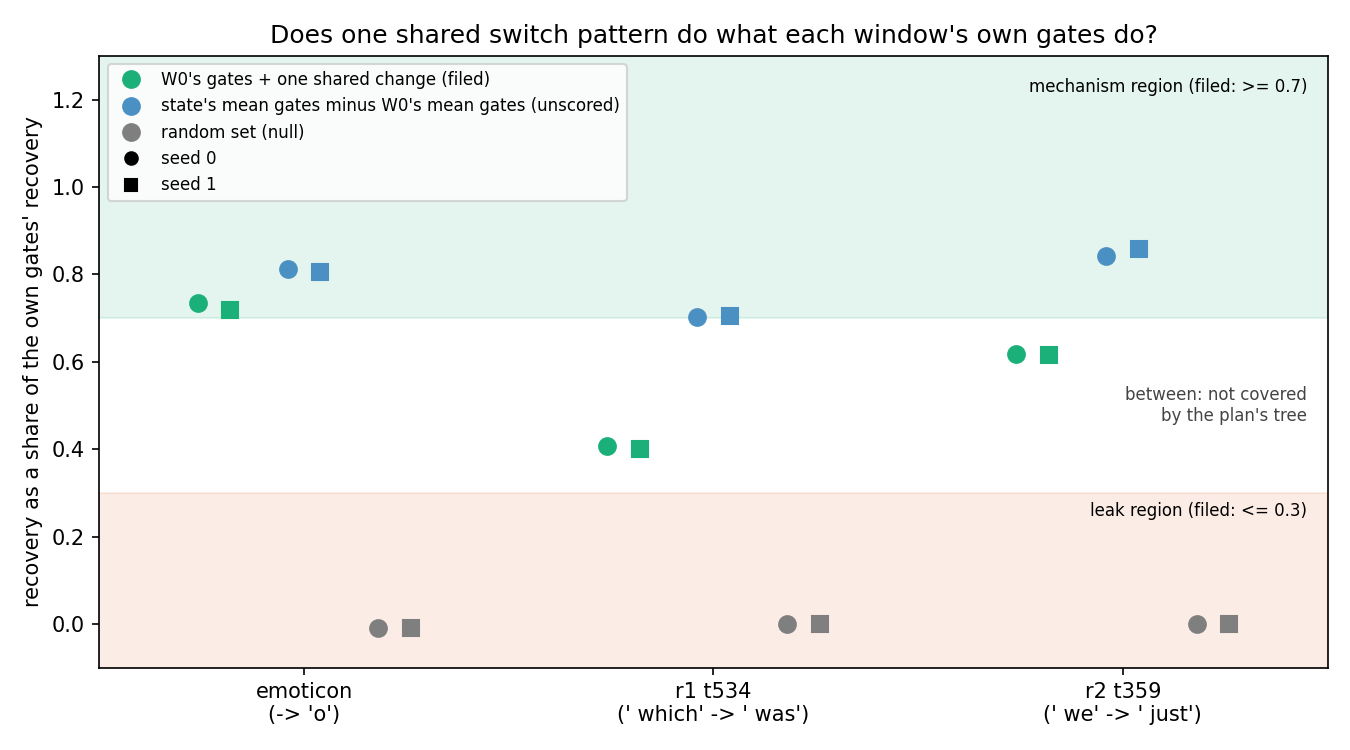

In [3]:
print(f"{'task':<14}{'seed':>5}{'shared/own':>12}{'(mean-ref)/own':>16}{'random/own':>12}")
for n, t in out["tasks"].items():
    for s, v in t["seeds"].items():
        r = v["rho"]
        print(f"{n[:13]:<14}{s:>5}{r['shared'] / r['trig']:>12.2f}{(r['mean'] - r['mean_W0']) / r['trig']:>16.2f}"
              f"{v['random_mean'] / r['trig']:>12.3f}")
fig("shared.png")

**Reading it.** On emoticon yes, narrowly; on the two word tasks the filed test fails. The green points are the shared
change's recovery as a share of the own values'. Emoticon sits just inside the mechanism region at 0.72 and 0.73. The
first word task reads 0.40 and the second 0.62, in the white band between the bars. Neither is in the leak region. The
random set gives back nothing, so which subcomponents are switched on matters.

The blue points are the unscored mean pattern, minus its reference. They sit at 0.70 to 0.86 on every task. That pattern
is fixed too: it holds no input-specific information from the updated model. A leak predicts that a fixed pattern
fails, so this argues against a leak. The caveat is that subtracting the reference assumes the effects add, which was
not tested.

**Why the two fixed patterns differ.** Write $g_0(x)$ for the original values at input $x$, and $m_0$, $m_1$ for the
original and updated mean values. With $s = m_1 - m_0$, the shared pattern is $\mathrm{clip}(g_0(x) + s)$ and the mean
pattern is $m_0 + s$. They differ by the clip and by the original model's own variation $g_0(x) - m_0$. Which of the
two lowers the shared pattern was not isolated.

## Is the pattern specific to the task?

**Reading it.** Yes. The orange bars in the first figure show a fine-tune to ` http` at the same trigger. Its shared
change lowers this task's target instead of raising it, by 0.07 to 0.30 of the switching effect. Its switched-on sets
overlap the task's own by 0.02 to 0.05. Why the sign is negative was not checked.

## Is the switched-on set the model's own machinery for the token?

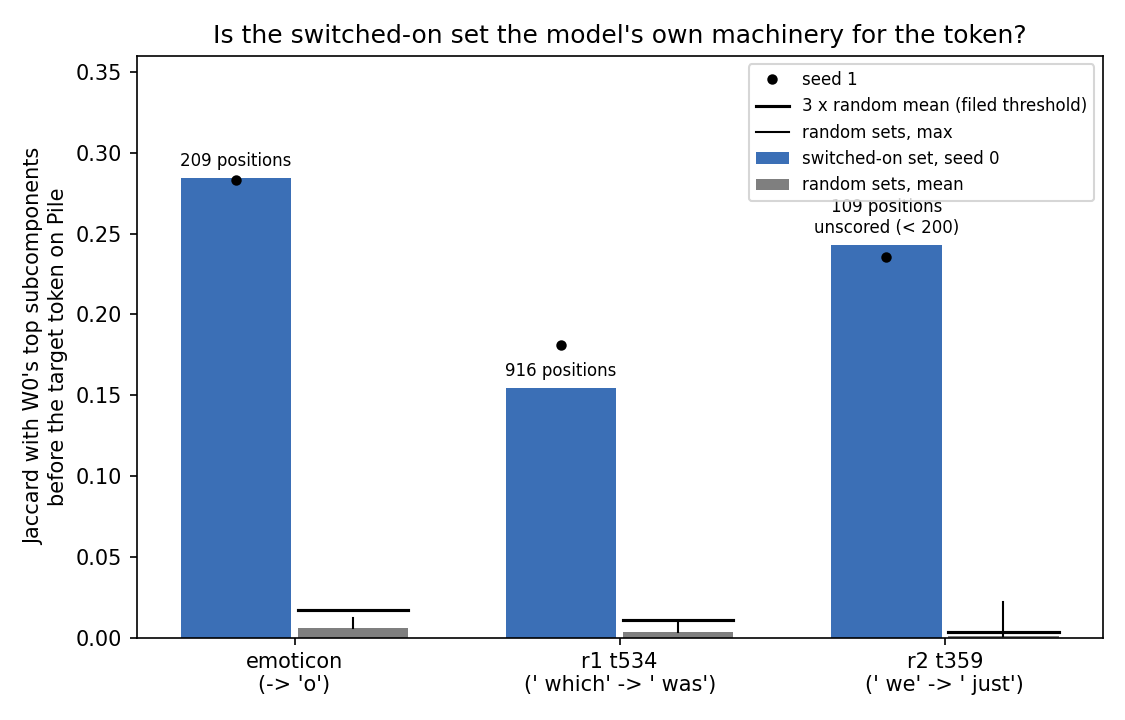

In [4]:
fig("natural.png")

**Reading it.** Yes, far above chance. The switched-on set's overlap with the subcomponents the original model switches
on before the same token in Pile text is 0.15 to 0.28. Random sets reach at most 0.024. The second word task had only 109
such positions, under the 200 required, so its bar is not scored. Fewer than half of the set are the model's usual
subcomponents for the token.

## Does the Pile adversary remove the switched-on set?

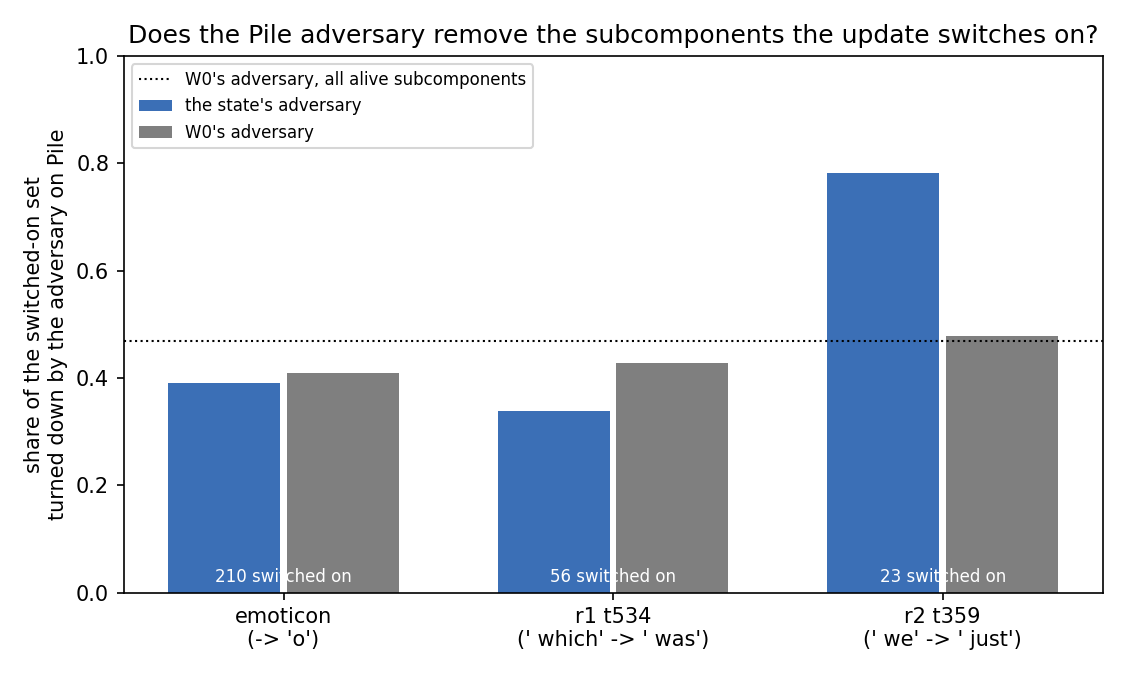

In [5]:
fig("adversary.png")

**Reading it.** Only on the second word task, where VPD's adversary on the updated model turns down 18 of its 23
switched-on subcomponents. The original model's adversary turns down 11 of the same set. On the other two tasks the
adversary turns down fewer than the original's does. Unscored, and one task.

## What we learned

One fixed pattern of importance values, chosen from training windows, brings most of the behaviour back on held-out
windows. So most of the switching effect does not need input-specific information, provided the reference subtraction
is fair. That pattern
is specific to the target token and partly overlaps the model's own subcomponents for it. So the "reveal" reading in
`GOALS.md` survives this control in substance. What is unresolved is why adding the fixed change on top of each
input's own values does worse on the word tasks than replacing them outright.

## How compelling is the evidence

Three tasks, two seeds each; the two seeds agree within 0.03 on every number. The random and wrong-target nulls sit near or
below zero. The mean pattern's argument rests on subtracting a reference that is far from zero, which assumes the
effects add. Everything is read at the trigger position on 73 to 106 held-out windows per task; nothing here says
whether the decomposition stays faithful elsewhere.

## Which branch of the plan's decision tree

The data meet the "mixed" branch's words: a pass on emoticon and a fail on both word tasks. But the tree took a fail to
mean the leak region, and the word tasks sit between the two filed bars. No branch interprets that band, and the
unscored mean pattern contradicts the mixed branch's reading. The tree does not decide this result; the call is the
user's.

## Surprises

- The filed shared-pattern test missed on both word tasks, in a band the plan did not interpret. A miss, not a reversal
  into the leak reading.
- A different target's change pushes this target down instead of leaving it alone.
- The fixed mean pattern beats the filed shared pattern on every task, and on the second word task beats the own values.
- The adversary turns down most of the second word task's switched-on set.

## What next

1. Rerun the shared pattern without the clip, and with the change only on the switched-on set: minutes on the debug
   queue. If the clip explains the gap, the miss is the pattern's construction and the mechanism reading stands.
2. Read the different target's pattern at ` http`. A rise there would make the negative sign plain competition.
3. Link the second word task's adversary result to the complement revert, which is already built.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | apparatus reproduces earlier runs | share within 0.05 or 0.1 of reference; original values recover 0 | within 0.001; 0 exactly | pass |
| P1 | the trigger carries the effect | own ≥ 0.7, every task and seed | 0.86–0.99 | pass |
| P2 | a shared pattern carries it | shared ÷ own ≥ 0.7, random ≤ 0.1; leak ≤ 0.3 | 0.72–0.73; 0.40; 0.62 | **fail**: emoticon mechanism, word tasks between |
| P3 | the pattern is the task's | different target ≤ 0.1 | −0.30 to −0.07 | pass |
| P4 | the set is the model's own | overlap ≥ 3 × random, ≥ 200 positions | 0.28, 0.15 scored; 0.24 unscored | pass |

## Not run

The shared pattern without the clip; a random null for the mean pattern; the different target read at its own token;
an additivity check; enough Pile positions for the second word task. By design: key-to-value tasks, component-training
states, the per-step version, the mask-capacity test.

## Provenance

`experiments/regating_leak/results/regating_leak.json`, sha256 `595be251d2be440c…`. MATS cluster job 28204, one L40,
139 s, $0, 2026-10-21.

## Amendment 1 (2026-10-21): what lowers the filed shared pattern?

The filed pattern keeps each input's original values and adds one fixed change on top, clipped to 0 to 1. The mean
pattern replaces the values by the updated model's average. We walked from one to the other in steps that each change
one thing:

| pattern | values at the trigger | differs from the row above by |
|---|---|---|
| shared, filed | each input's original values plus the change, clipped | — |
| no clip | the same, not clipped | the clip |
| mean plus change | the original model's average plus the change, the same for every input | the original model's input-to-input variation |
| mean | the updated model's average | dead subcomponents |

Two more readings. The *no-change mean* is the original average with no change at all: what averaging does by itself.
The *switched-on set only* keeps the change only where it exceeds 0.3, the set E18's random null and overlap used.
None of these patterns reads the updated model on the held-out input. Filed prediction: the input-to-input variation
carries at least half of the gap on both word tasks.

status done, 39 s; gates passed: True


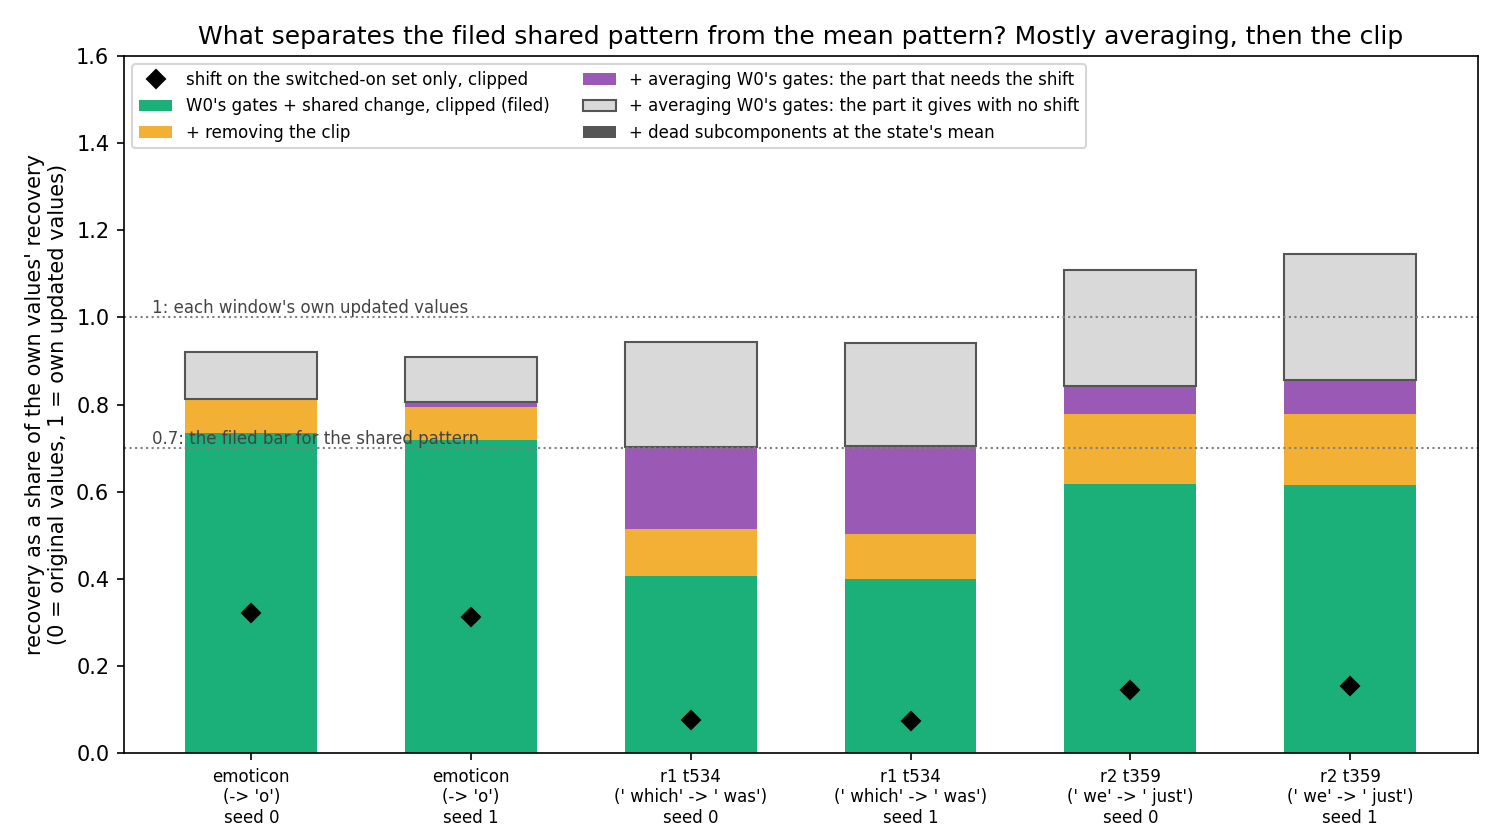

In [6]:
a1 = json.loads((EXP / "results" / "regating_leak_amend1.json").read_text())
print(f"status {a1['status']}, {a1['seconds']:.0f} s; gates passed: {a1['gate_pass']}")
fig("amend1.png")

**Reading it.** Averaging the original values closes most of the gap; the clip closes a fifth to a third; the dead
subcomponents nothing. Each bar climbs from the filed pattern, in green, to the mean pattern at its top. On the word
tasks about half the gap, the light grey block, is what averaging gives with no change at all. The purple block is the
change working better on the average than on each input's own values. A fixed change on the average recovers 0.70 to
0.86 of the own values net of the no-change block, on every task. Added to each input's own values, unclipped, it
recovers 0.50 to 0.81. So the filed test's miss comes from how a fixed change meets the original values, not from
anything the updated model knows about the input. That is the mechanism reading, pending the user's confirmation.

In [7]:
print(f"{'task':<14}{'seed':>5}{'shared':>8}{'no clip':>9}{'mean+chg':>10}{'no-chg':>8}{'set only':>10}")
for n, t in a1["tasks"].items():
    for s, v in t["seeds"].items():
        R = v["R"]
        print(f"{n[:13]:<14}{s:>5}{R['shared']:>8.2f}{R['noclip']:>9.2f}{R['mean_s']:>10.2f}{R['mean_W0']:>8.2f}{R['S_on']:>10.2f}")

task           seed  shared  no clip  mean+chg  no-chg  set only
emoticon          0    0.73     0.81      0.92    0.11      0.32
emoticon          1    0.72     0.79      0.91    0.10      0.31
r1_t534_v369      0    0.41     0.51      0.94    0.24      0.07
r1_t534_v369      1    0.40     0.50      0.94    0.24      0.07
r2_t359_v816      0    0.62     0.78      1.11    0.27      0.14
r2_t359_v816      1    0.62     0.78      1.15    0.29      0.15


**The switched-on set carries the smaller part.** The black diamonds keep the change on the switched-on set only.
On the first word task they recover 0.07, against 0.40 for the whole change. The second reads 0.15 against 0.62. Most of the filed
pattern's recovery comes from the many alive subcomponents whose change is below 0.3. E18's random null moved only the
set's values, so the larger part has no null yet. That null is the next run.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| A1_repeat | repeats E18 | shared and mean within 0.02; no change recovers 0 | identical; 0.0 | pass |
| A1_P1 | the original model's variation lowers the filed pattern | share ≥ 0.5 on word tasks | 0.80, 0.81, 0.67, 0.69 | **pass** |

Not run: a random null for the whole change; other orders of the path. Results
`results/regating_leak_amend1.json`, sha256 `af5222ee95402…`; MATS cluster job 28260, 39 s, $0.

## Amendment 2 (2026-10-21): does it matter which subcomponent gets which value?

The user does not back the mechanism reading; it is the leading hypothesis, with three parts. The change is the same
for every input, it is specific to which subcomponents receive it, and it is enough on its own. This run tests the
second part only.

We took the shared change and reassigned its values at random among each matrix's alive subcomponents, twenty times.
The shuffle keeps every matrix's values and their sum, so a change that works by "raising this many values somewhere
in the matrix" would survive it. Filed prediction: the shuffled change recovers at most a fifth of what the unshuffled
change recovers, on every task and seed. As an unscored extra, we kept the unclipped change only within one bin of its
size, to see where its recovery sits.

status done, 88 s; gate passed: True


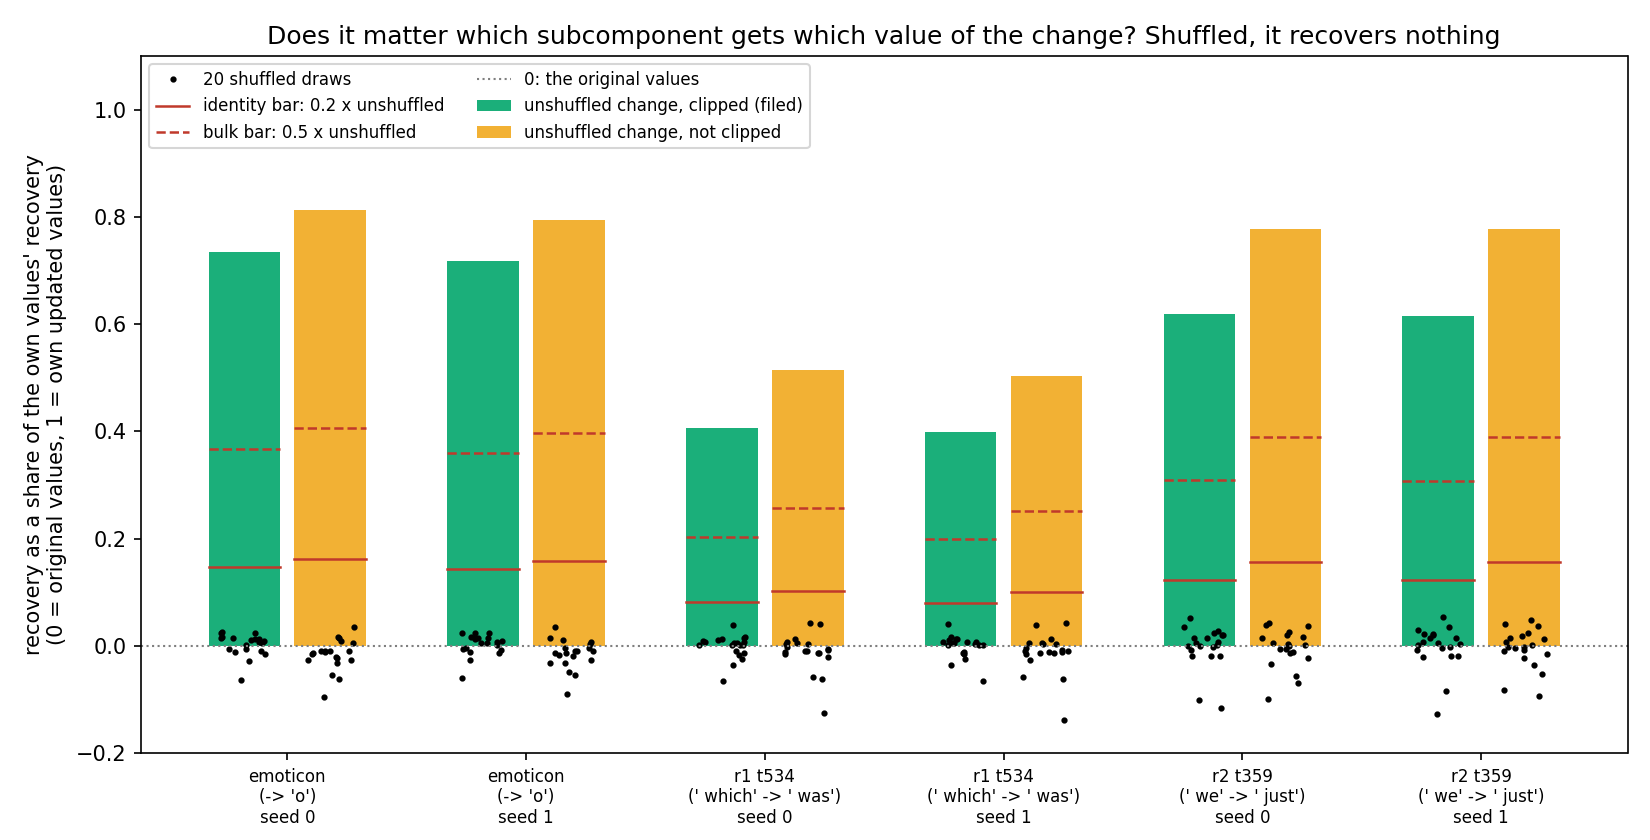

In [8]:
a2 = json.loads((EXP / "results" / "regating_leak_amend2.json").read_text())
print(f"status {a2['status']}, {a2['seconds']:.0f} s; gate passed: {a2['gate_pass']}")
fig("amend2_null.png")

**Reading it.** Yes, identity matters: shuffled, the change recovers nothing on every task and seed. The bars are the
unshuffled change, clipped in green and unclipped in yellow. The black dots, the twenty shuffled draws, scatter around
zero, far below the solid red identity bar. Their mean is within half a percent of zero for the clipped change. Unclipped
it is slightly negative, as expected when moved negative values flip the sign of subcomponents that are off. This
supports the second part of the hypothesis; it does not test the other two.

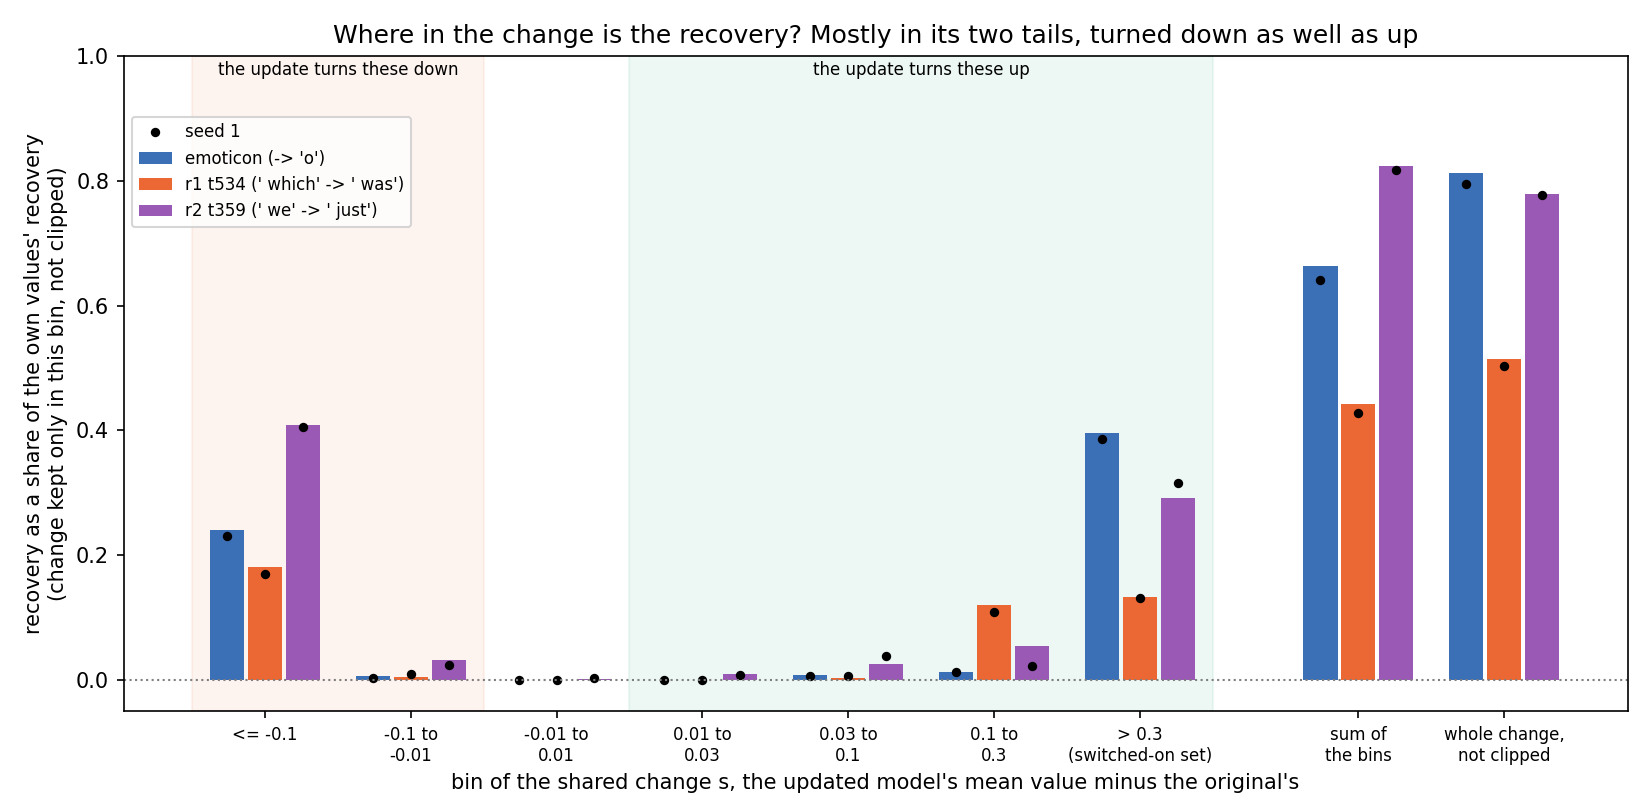

In [9]:
fig("amend2_bins.png")

**Reading it.** The recovery sits in the two tails of the change, and the lower tail is as large as the upper one.
The left bars keep only the subcomponents whose value the update lowers by more than 0.1. On emoticon they recover
about a quarter of the effect, against 0.40 for the switched-on set at the right. On both word tasks they recover more
than the switched-on set does. The roughly nine thousand entries near zero carry nothing. One caveat: unclipped, a
lowered value can go below zero and flip its subcomponent's sign, and that part was not measured.

**Surprise.** Everything E18 checked about the change, its random null and its overlap with the model's own
subcomponents for the token, looked only at the switched-on set. The subcomponents the update turns down carry a large
part of the effect and have had no test of their own. Next: are they the original model's subcomponents for competing
tokens; does their share survive the clip; does a shuffle that keeps each value's sign also recover nothing.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| A2_repeat | repeats Amendment 1 | within 1e-6 | identical | pass |
| A2_P1 | the clipped change needs its own subcomponents | shuffled ÷ unshuffled ≤ 0.2 | −0.005 to 0.003 | **pass** |
| A2_P2 | the unclipped change needs its own subcomponents | the same | −0.026 to −0.007 | **pass** |

Not run: a sign-preserving shuffle; a shuffle across matrices; the bins with the clip. Results
`results/regating_leak_amend2.json`, sha256 `37c0225d49d80…`; MATS cluster job 28302, 88 s, $0.

## Amendment 3 (2026-10-21): tests the hypothesis could fail

> **A filed prediction failed.** The updated model's own values, with the fixed change removed, still give back up to
> a third of the effect. The filed prediction said they give back nothing. The failure goes to the user before
> anything else is run.

The hypothesis has three parts. The change to Γ's values is the same for every input; it is specific to which
subcomponents receive it; and it is enough on its own. A leak is the failure of the third part. Here $g_1(x)$ is the
updated model's importance values at the trigger of window $x$, and $s$ is the fixed change, the updated mean minus
the original mean. We ran one test per part, each one the hypothesis could fail:

- **The remainder alone.** Keep each window's own updated values and remove the fixed change, $\mathrm{clip}(g_1(x) - s)$.
  Under the hypothesis this gives back nothing; the filed bar was 0.15, and 0.3 or more reads a leak.
- **Another window's values.** Give each window another window's updated values. Under the hypothesis they do about
  as well as its own; the filed bar was 0.8.
- **Whose gain it follows.** Under another window's values, does a window's gain track its own gain or the donor's?
  A leak that carries "how strongly to predict the target here" would make it track the donor's.
- **Each half of the change, shuffled.** The turned-up and the turned-down entries of $s$, each moved at random among
  the subcomponents that could receive them. Under the hypothesis, shuffled, each gives back nothing.

status done, 79 s; gate passed: True


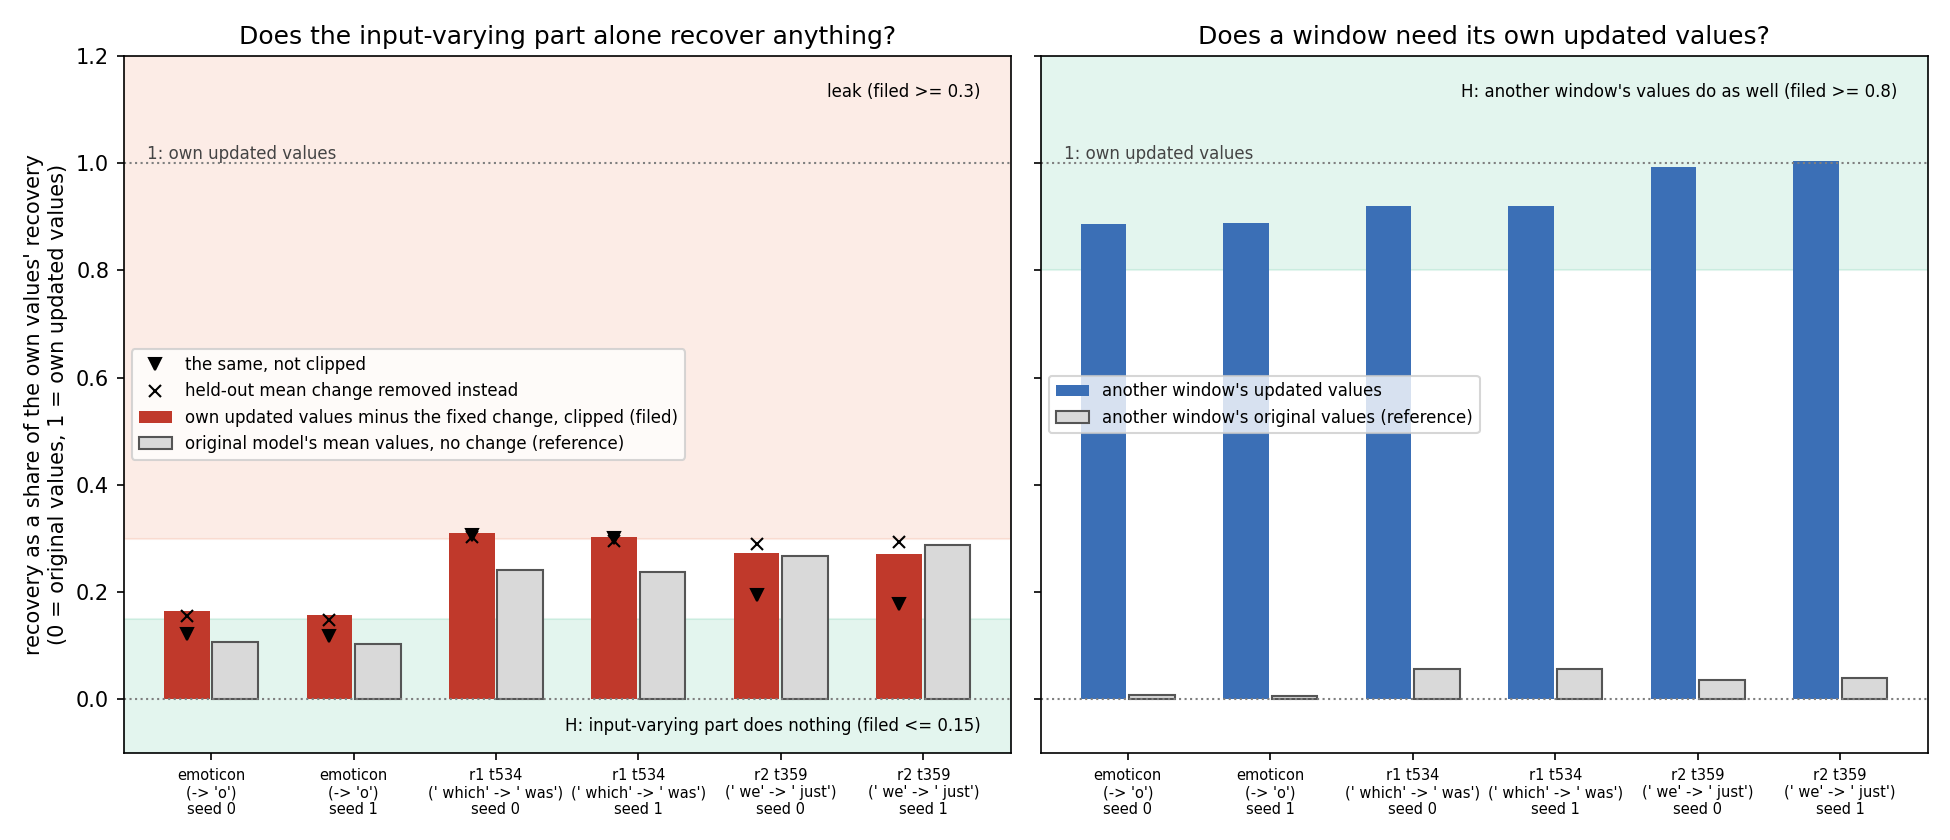

In [10]:
a3 = json.loads((EXP / "results" / "regating_leak_amend3.json").read_text())
print(f"status {a3['status']}, {a3['seconds']:.0f} s; gate passed: {a3['gate_pass']}")
fig("amend3_tests.png")

**Reading it.** The left panel fails the hypothesis as filed; the right panel supports it. On the left, the red bars
are the remainder alone. It gives back 0.16 on emoticon and 0.27 on the second word task. On the first word task it
gives back 0.30 to 0.31, at the edge of the orange leak band. The grey bars beside them are the original model's
averaged values, with no change at all. They give back nearly as much: 0.24 on the first word task, and as much on
the second. On the right, another window's updated values give back 0.89 to 1.00 on every state.
Another window's original values give back 0.01 to 0.06. So at most a tenth of the effect needs the window's own values.

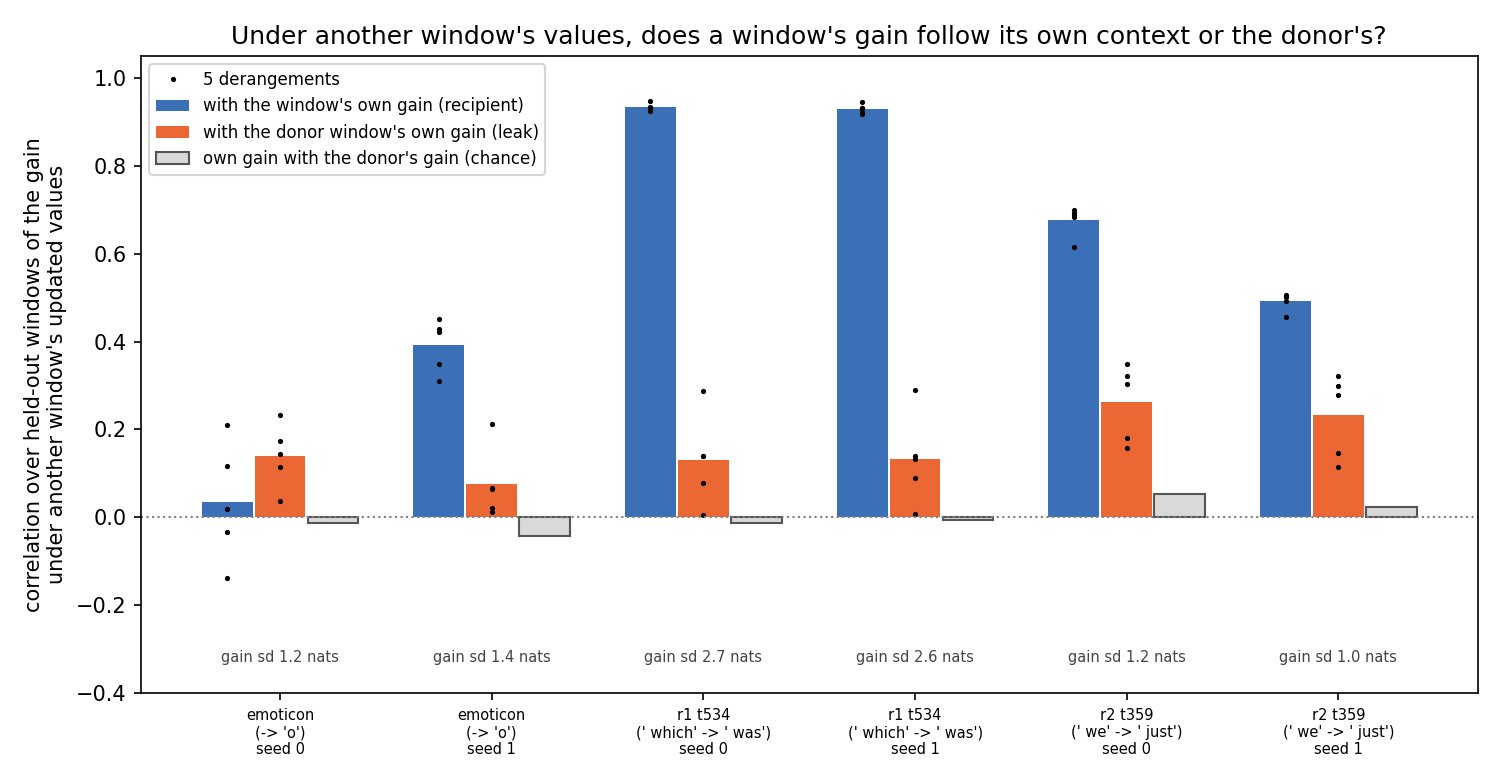

In [11]:
fig("amend3_donor.png")

**Reading it.** Under another window's values, the gain follows the window's own context on five of six states. The
blue bars correlate each window's gain with its own gain and read 0.39 to 0.93. The orange bars correlate it with the
donor's gain and read 0.08 to 0.26, and chance, in grey, sits near zero. On emoticon seed 0 neither correlation is
clear. The emoticon windows are alike, so the test has little to grip there. No state follows the donor.

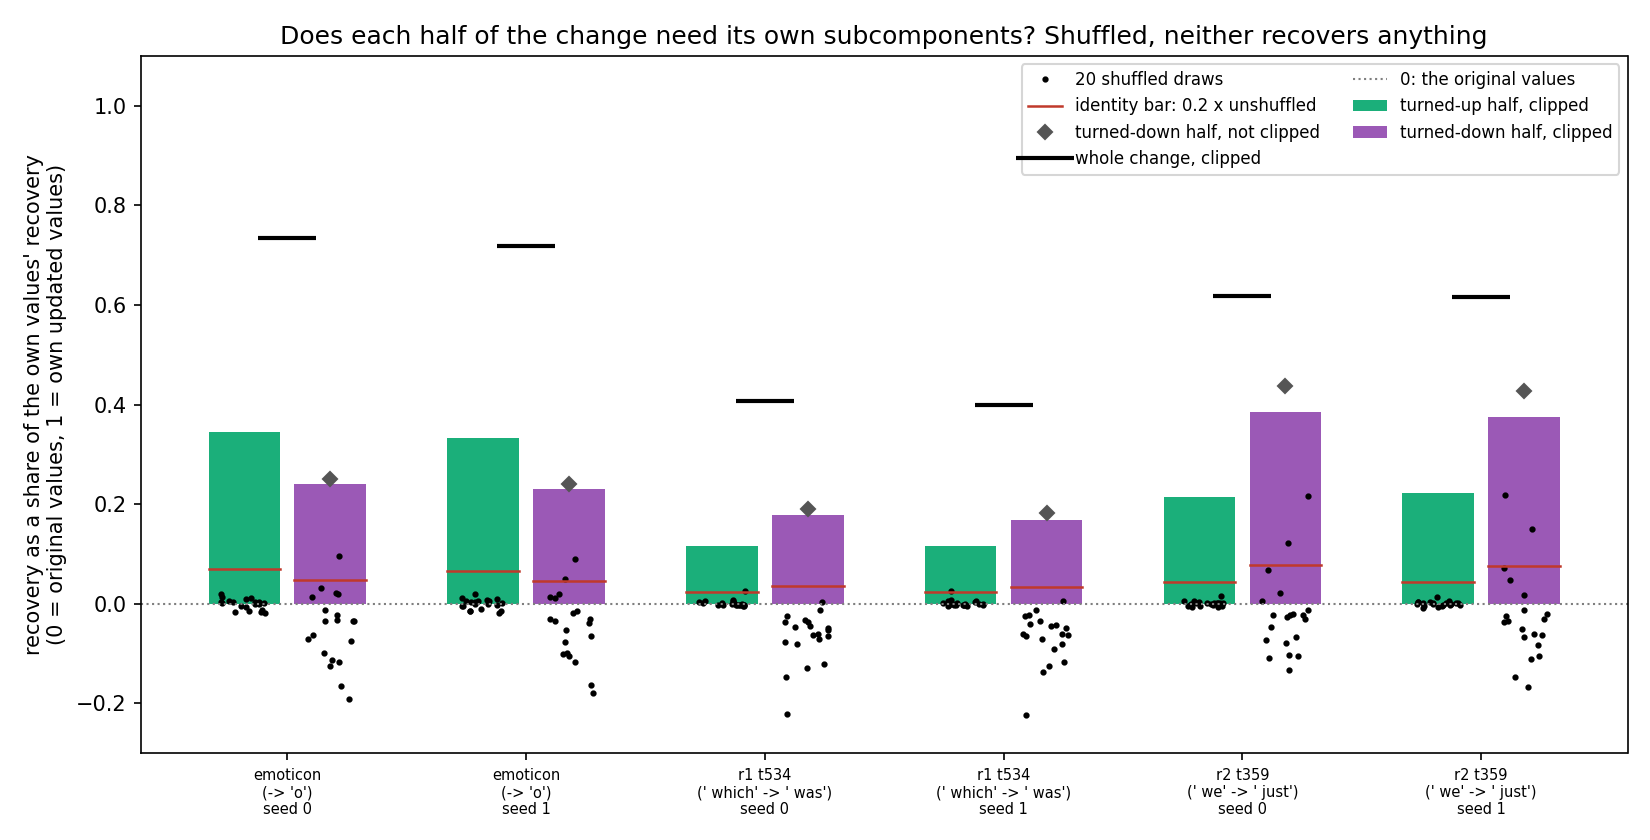

In [12]:
fig("amend3_halves.png")

**Reading it.** Both halves of the change need their own subcomponents. Shuffled, the turned-up half, in green, gives
back nothing; the turned-down half, in purple, gives back less than nothing. The grey diamonds are the turned-down half
without the clip. The clipped bars keep 0.89 to 0.98 of them, so the turned-down half is a real switch-off rather than
a flipped sign. The halves add up to the whole change, the black line, on the second word task only.

**What it means for the hypothesis.** The first two parts survived tests they could have failed. The third failed as
filed: the input-varying part does something on its own, about 0.3 of the effect on the first word task. Yet that part
need not come from the same input, since another window's values do nearly as well. One candidate reading, **not
verified**, is that the remainder carries no input-specific information. It may carry a change in the variation all
inputs share, or only the cost of replacing the original model's own per-window values. The averaged original values
in the first figure point that way, but do not test it. The number that would separate the readings is the remainder
taken from another window: $\mathrm{clip}(g_1(x') - s)$ placed on window $x$. Near the own remainder, nothing
input-specific leaks. Near the no-change average or below, something tied to the window does. The hypothesis is not
established.

**Also reported.** Placed on Pile positions away from any trigger, the change raises the emoticon target by about a
nat, a fifth of its effect at the trigger. On the word tasks it slightly lowers the target, so there it works only in
its context.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| A3_repeat | repeats Amendment 2 | within 1e-6 | identical | pass |
| A3_P1 | the remainder alone recovers nothing | ≤ 0.15; ≥ 0.3 leak | 0.16, 0.30 to 0.31, 0.27 | **fail** |
| A3_P2 | another window's values do as well | ≥ 0.8 | 0.89 to 1.00 | **pass** |
| A3_P3 | the gain follows the recipient | donor never 0.2 above own | 5 recipient, 1 neither | **pass** |
| A3_P4 | the turned-down half needs its own subcomponents | shuffled ÷ unshuffled ≤ 0.2 | −0.41 to −0.06 | **pass** |
| A3_P5 | the turned-up half needs its own subcomponents | the same | at most 0.009 | **pass** |

Not run: the remainder from another window; a planted-leak control for the donor test; the turned-down set's overlap
with competing tokens' subcomponents. Results `results/regating_leak_amend3.json`, sha256 `0cb13499ad792…`; MATS
cluster job 28308, 79 s, $0.